In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn import linear_model, preprocessing, model_selection, metrics, pipeline

In [3]:
df = pd.read_csv("https://raw.githubusercontent.com/abulbasar/data/refs/heads/master/credit-default.csv")
df

,checking_balance,months_loan_duration,credit_history,purpose,amount,savings_balance,employment_length,installment_rate,personal_status,other_debtors,...,property,age,installment_plan,housing,existing_credits,default,dependents,telephone,foreign_worker,job
0,< 0 DM,6,critical,radio/tv,1169,unknown,> 7 yrs,4,single male,none,...,real estate,67,none,own,2,1,1,yes,yes,skilled employee
1,1 - 200 DM,48,repaid,radio/tv,5951,< 100 DM,1 - 4 yrs,2,female,none,...,real estate,22,none,own,1,2,1,none,yes,skilled employee
2,unknown,12,critical,education,2096,< 100 DM,4 - 7 yrs,2,single male,none,...,real estate,49,none,own,1,1,2,none,yes,unskilled resident
3,< 0 DM,42,repaid,furniture,7882,< 100 DM,4 - 7 yrs,2,single male,guarantor,...,building society savings,45,none,for free,1,1,2,none,yes,skilled employee
4,< 0 DM,24,delayed,car (new),4870,< 100 DM,1 - 4 yrs,3,single male,none,...,unknown/none,53,none,for free,2,2,2,none,yes,skilled employee
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,unknown,12,repaid,furniture,1736,< 100 DM,4 - 7 yrs,3,female,none,...,real estate,31,none,own,1,1,1,none,yes,unskilled resident
996,< 0 DM,30,repaid,car (used),3857,< 100 DM,1 - 4 yrs,4,divorced male,none,...,building society savings,40,none,own,1,1,1,yes,yes,mangement self-employed
997,unknown,12,repaid,radio/tv,804,< 100 DM,> 7 yrs,4,single male,none,...,other,38,none,own,1,1,1,none,yes,skilled employee
998,< 0 DM,45,repaid,radio/tv,1845,< 100 DM,1 - 4 yrs,4,single male,none,...,unknown/none,23,none,for free,1,2,1,yes,yes,skilled employee


In [5]:
df.default.value_counts() # default = 2 indicates the customer defaulted on loan

default
1    700
2    300
Name: count, dtype: int64

In [12]:
target = "default"
X = pd.get_dummies(df.drop(columns=[target]))
y = np.where(df[target] == 2, 1, 0)

X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y, test_size = 0.2, random_state=123)

pipe = pipeline.Pipeline([
    ('scaler', preprocessing.StandardScaler()),
    ('est', linear_model.LogisticRegression(max_iter=1000)),
])

pipe.fit(X_train, y_train)

y_train_prob = pipe.predict_proba(X_train)[:, 1]
y_test_prob = pipe.predict_proba(X_test)[:, 1]

prob_threshold = 0.5

y_train_pred = np.where(y_train_prob>prob_threshold, 1, 0)
y_test_pred = np.where(y_test_prob>prob_threshold, 1, 0)

print("test accuracy", metrics.accuracy_score(y_test, y_test_pred))
print("test precision", metrics.precision_score(y_test, y_test_pred))
print("test recall", metrics.recall_score(y_test, y_test_pred))
print("test f1", metrics.f1_score(y_test, y_test_pred))
print("test confusion\n", metrics.confusion_matrix(y_test, y_test_pred))


test accuracy 0.79
test precision 0.6610169491525424
test recall 0.639344262295082
test f1 0.65
test confusion
 [[119  20]
 [ 22  39]]


In [9]:
# In which quadrant the bank makes money 

In [13]:
prob_threshold = 0.3

y_train_pred = np.where(y_train_prob>prob_threshold, 1, 0)
y_test_pred = np.where(y_test_prob>prob_threshold, 1, 0)

print("test accuracy", metrics.accuracy_score(y_test, y_test_pred))
print("test precision", metrics.precision_score(y_test, y_test_pred))
print("test recall", metrics.recall_score(y_test, y_test_pred))
print("test f1", metrics.f1_score(y_test, y_test_pred))
print("test confusion\n", metrics.confusion_matrix(y_test, y_test_pred))

test accuracy 0.765
test precision 0.5813953488372093
test recall 0.819672131147541
test f1 0.6802721088435374
test confusion
 [[103  36]
 [ 11  50]]


In [14]:
prob_threshold = 0.8

y_train_pred = np.where(y_train_prob>prob_threshold, 1, 0)
y_test_pred = np.where(y_test_prob>prob_threshold, 1, 0)

print("test accuracy", metrics.accuracy_score(y_test, y_test_pred))
print("test precision", metrics.precision_score(y_test, y_test_pred))
print("test recall", metrics.recall_score(y_test, y_test_pred))
print("test f1", metrics.f1_score(y_test, y_test_pred))
print("test confusion\n", metrics.confusion_matrix(y_test, y_test_pred))

test accuracy 0.74
test precision 0.8461538461538461
test recall 0.18032786885245902
test f1 0.2972972972972973
test confusion
 [[137   2]
 [ 50  11]]


In [30]:
scores = []
for prob_threshold in np.linspace(0.01, 0.9, 30):
    y_train_pred = np.where(y_train_prob>prob_threshold, 1, 0)
    y_test_pred = np.where(y_test_prob>prob_threshold, 1, 0)
    scores.append({
        'accuracy': metrics.accuracy_score(y_test, y_test_pred),
        'precision': metrics.precision_score(y_test, y_test_pred),
        'recall': metrics.recall_score(y_test, y_test_pred),
        'f1': metrics.f1_score(y_test, y_test_pred),
        'threshold': prob_threshold
    })

a = pd.DataFrame.from_records(scores)
a

,accuracy,precision,recall,f1,threshold
0,0.315,0.306122,0.983607,0.466926,0.010000
1,0.395,0.333333,0.983607,0.497925,0.040690
2,0.470,0.363636,0.983607,0.530973,0.071379
3,0.555,0.404110,0.967213,0.570048,0.102069
4,0.620,0.443609,0.967213,0.608247,0.132759
5,0.615,0.437500,0.918033,0.592593,0.163448
6,0.650,0.462185,0.901639,0.611111,0.194138
7,0.670,0.477876,0.885246,0.620690,0.224828
8,0.695,0.500000,0.885246,0.639053,0.255517
9,0.740,0.549451,0.819672,0.657895,0.286207


In [38]:
threshold_max = a.sort_values('f1', ascending=False).iloc[0].threshold
f1_max = a.sort_values('f1', ascending=False).iloc[0].f1
threshold_max, f1_max

(np.float64(0.31689655172413794), np.float64(0.6620689655172414))

Text(0.3485862068965518, 0.3, 'Max f1 score: 0.66\n at threshold: 0.32')

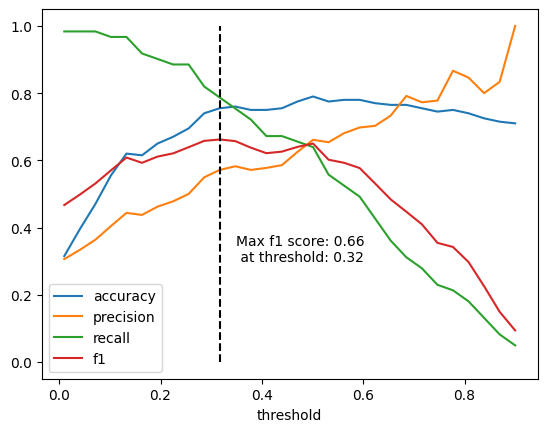

In [44]:
a.index = a.threshold
a.drop(columns=['threshold']).plot.line()

plt.vlines(threshold_max, 0, 1, ls = '--', color = "black")

plt.text(threshold_max * 1.1,  0.3, f"Max f1 score: {f1_max:.2f}\n at threshold: {threshold_max:.2f}")

In [ ]:
# Plot total amount in FN and total amount in TN in the above chart. 

In [46]:
auc = metrics.roc_auc_score(y_test, y_test_prob) #
auc

0.83193772850572

Text(0.5, 1.0, 'ROC, auc: 0.83')

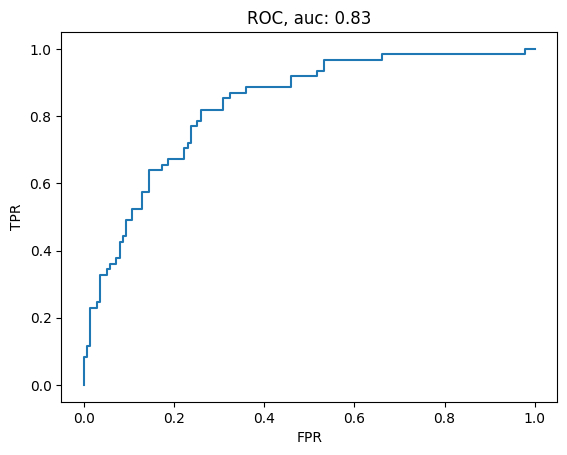

In [57]:
fpr, tpr, thresholds = metrics.roc_curve(y_test, y_test_prob)

plt.plot(fpr, tpr)

plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title(f'ROC, auc: {auc:.2f}')